# HỆ THỐNG PHÂN KHÚC KHÁCH HÀNG LAI GHÉP VÀ ĐỒNG THUẬN 3 MÔ HÌNH (TRI-MODEL HYBRID & CONSENSUS ENSEMBLE)
## Kết Hợp Thứ Bậc (Hierarchical) - Phân Hoạch (K-Means) - Mật Độ (DBSCAN) Trên Bộ Đặc Trưng RFM

**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)  
**Nhóm thực hiện:** Nhóm 05 - Lớp DCT124C1 - Trường Đại học Sài Gòn (SGU)


In [1]:
import os
import sys

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

if current not in sys.path:
    sys.path.insert(0, current)
os.chdir(current)
print("Working directory set to:", os.getcwd())

import warnings
import time
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✅ Đã nạp thành công toàn bộ thư viện cần thiết!")


Working directory set to: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy


✅ Đã nạp thành công toàn bộ thư viện cần thiết!


### 1. Kiến Trúc Hệ Thống Lai Ghép & Đồng Thuận 3 Mô Hình (Tri-Model Architecture)

Mô hình đơn lẻ luôn mang các khiếm khuyết nội tại do giả định hình học:
1. **K-Means**: Hội tụ nhanh $\mathcal{O}(NK)$ nhưng nhạy cảm với khởi tạo tâm ban đầu và hoàn toàn bất lực trước điểm ngoại lai (Outliers kéo lệch tâm).
2. **Hierarchical (Ward)**: Xây dựng cấu trúc phả hệ tự nhiên rất tốt nhưng độ phức tạp tính toán lớn $\mathcal{O}(N^2)$ và không có khả năng dự đoán trực tiếp điểm mới.
3. **DBSCAN**: Phân lập điểm mật độ tùy ý và lọc nhiễu xuất sắc nhưng không thể phân vùng toàn bộ không gian khách hàng khi mật độ chênh lệch lớn.

**Hệ thống Tri-Model Hybrid & Consensus giải quyết bài toán qua 3 tầng:**
- **Tầng 1 (Structural Initialization)**: Dùng Hierarchical Ward $K=4$ để trích xuất cấu trúc tâm tự nhiên từ dữ liệu Train.
- **Tầng 2 (Centroid Refinement)**: KMeans nhận trực tiếp các tâm này làm tọa độ khởi tạo (`init=h_centroids`), hội tụ tối ưu chỉ sau 2 vòng lặp.
- **Tầng 3 (Density & Anomaly Isolation)**: DBSCAN ($\varepsilon=0.6, \text{MinPts}=10$) quét các điểm để phân tách nhóm **Super Whales** (chi tiêu cực đoan).
- **Consensus Engine**: Bầu cử đồng thuận giữa các thuật toán để chỉ ra:
  - *Core Consensus (Đồng thuận lõi)*: Khách hàng được xếp nhóm với độ tin cậy tuyệt đối.
  - *Boundary Contested (Biên tranh chấp)*: Khách hàng ở vùng chuyển giao cần kích cầu.
  - *Super Whales (Cá mập siêu chi tiêu)*: Khách hàng VIP cần chăm sóc 1-1.


In [2]:
# 1. Đọc dữ liệu RFM đã chia tách Train / Validation / Test
train_rfm = pd.read_csv("data/rfm_train.csv")
val_rfm   = pd.read_csv("data/rfm_val.csv")
test_rfm  = pd.read_csv("data/rfm_test.csv")

features = ['Recency', 'Frequency', 'Monetary']

# 2. Xử lý Log1p và Chuẩn hóa StandardScaler (Fit trên Train)
scaler = StandardScaler()
X_train_log = np.log1p(train_rfm[features])
X_train_scaled = scaler.fit_transform(X_train_log)

X_val_log = np.log1p(val_rfm[features])
X_val_scaled = scaler.transform(X_val_log)

X_test_log = np.log1p(test_rfm[features])
X_test_scaled = scaler.transform(X_test_log)

print(f"📊 Kích thước dữ liệu:")
print(f" - Train set: {X_train_scaled.shape[0]:,} khách hàng")
print(f" - Validation set: {X_val_scaled.shape[0]:,} khách hàng")
print(f" - Test set: {X_test_scaled.shape[0]:,} khách hàng")


📊 Kích thước dữ liệu:
 - Train set: 2,736 khách hàng
 - Validation set: 684 khách hàng
 - Test set: 855 khách hàng


In [3]:
# ==============================================================================
# 2. HUẤN LUYỆN CHUỖI 3 TẦNG (TRI-STAGE TRAINING)
# ==============================================================================
print("🚀 Bắt đầu huấn luyện chuỗi 3 tầng Tri-Stage Hybrid...")
t0 = time.time()

# --- TẦNG 1: Hierarchical Agglomerative (Ward Linkage, K=4) ---
t_h = time.time()
h_model = AgglomerativeClustering(n_clusters=4, linkage='ward', metric='euclidean')
h_labels = h_model.fit_predict(X_train_scaled)
# Trích xuất tâm cụm thực nghiệm từ Hierarchical
h_centroids = np.array([X_train_scaled[h_labels == c].mean(axis=0) for c in range(4)])
time_h = (time.time() - t_h) * 1000
print(f"✅ Tầng 1: Hierarchical hoàn thành ({time_h:.1f}ms) -> Đã trích xuất 4 tâm cụm hạt giống.")

# --- TẦNG 2: K-Means Refinement với tâm khởi tạo từ Hierarchical ---
t_km = time.time()
km_guided = KMeans(
    n_clusters=4,
    init=h_centroids,
    n_init=1,
    algorithm='lloyd',
    max_iter=300,
    random_state=42
)
km_labels = km_guided.fit_predict(X_train_scaled)
time_km = (time.time() - t_km) * 1000
print(f"✅ Tầng 2: K-Means Refinement hoàn thành ({time_km:.1f}ms) -> Hội tụ sau {km_guided.n_iter_} vòng lặp | Inertia: {km_guided.inertia_:.2f}.")

# --- TẦNG 3: DBSCAN quét mật độ lọc Super Whales ---
t_db = time.time()
db_model = DBSCAN(eps=0.6, min_samples=10, metric='euclidean')
db_labels = db_model.fit_predict(X_train_scaled)
time_db = (time.time() - t_db) * 1000
n_whales = int(np.sum(db_labels == -1))
print(f"✅ Tầng 3: DBSCAN quét mật độ hoàn thành ({time_db:.1f}ms) -> Phân lập {n_whales} khách hàng Super Whales/Nhiễu.")

total_train_time = (time.time() - t0) * 1000
print(f"⏱️ Tổng thời gian huấn luyện toàn chuỗi: {total_train_time:.1f}ms")


🚀 Bắt đầu huấn luyện chuỗi 3 tầng Tri-Stage Hybrid...
✅ Tầng 1: Hierarchical hoàn thành (117.9ms) -> Đã trích xuất 4 tâm cụm hạt giống.


✅ Tầng 2: K-Means Refinement hoàn thành (46.1ms) -> Hội tụ sau 7 vòng lặp | Inertia: 2490.42.
✅ Tầng 3: DBSCAN quét mật độ hoàn thành (29.2ms) -> Phân lập 43 khách hàng Super Whales/Nhiễu.
⏱️ Tổng thời gian huấn luyện toàn chuỗi: 193.9ms


In [4]:
# ==============================================================================
# 3. XÂY DỰNG BỘ MÁY ĐỒNG THUẬN (CONSENSUS CLUSTERING ENGINE)
# ==============================================================================
# Bước 3.1: Đồng bộ nhãn giữa Hierarchical và K-Means (Hungarian Matching)
cost_matrix = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        cost_matrix[i, j] = -np.sum((h_labels == i) & (km_labels == j))
row_ind, col_ind = linear_sum_assignment(cost_matrix)
h_to_km_map = {row_ind[k]: col_ind[k] for k in range(4)}
h_labels_aligned = np.array([h_to_km_map[x] for x in h_labels])

# Bước 3.2: Xác định mức độ đồng thuận
agreement_mask = (km_labels == h_labels_aligned)
whale_mask = (db_labels == -1)

# Phân loại 3 tầng độ tin cậy
# 1. Core Consensus: 2 mô hình đồng thuận 100% VÀ không phải ngoại lai DBSCAN
core_consensus_mask = agreement_mask & (~whale_mask)
# 2. Contested / Boundary: 2 mô hình bất đồng ý kiến (nằm ở ranh giới biên)
boundary_mask = (~agreement_mask) & (~whale_mask)
# 3. Super Whales: DBSCAN cô lập chi tiêu cực đoan
whales_mask = whale_mask

n_total = len(train_rfm)
n_core = int(np.sum(core_consensus_mask))
n_bound = int(np.sum(boundary_mask))
n_w = int(np.sum(whales_mask))

print("=" * 90)
print("             KẾT QUẢ ĐỒNG THUẬN PHÂN CỤM TRI-MODEL TRÊN TẬP TRAIN (2,736 KHÁCH HÀNG)           ")
print("=" * 90)
df_tiers = pd.DataFrame([
    {"Phân tầng độ tin cậy": "1. Core Consensus (Đồng thuận lõi 100%)", "Số lượng KH": f"{n_core:,}", "Tỷ lệ (%)": f"{n_core/n_total*100:.2f}%", "Ý nghĩa": "Phân khúc chuẩn xác, độ tin cậy tuyệt đối"},
    {"Phân tầng độ tin cậy": "2. Boundary / Contested (Biên tranh chấp)", "Số lượng KH": f"{n_bound:,}", "Tỷ lệ (%)": f"{n_bound/n_total*100:.2f}%", "Ý nghĩa": "Khách hàng ở vùng chuyển dịch giữa 2 nhóm"},
    {"Phân tầng độ tin cậy": "3. Super Whales (Dị biệt / Cá mập)", "Số lượng KH": f"{n_w:,}", "Tỷ lệ (%)": f"{n_w/n_total*100:.2f}%", "Ý nghĩa": "Khách hàng siêu chi tiêu/tần suất cực cao"},
])
print(df_tiers.to_string(index=False))
print("-" * 90)
print(f"🎯 Chỉ số nhất quán giữa K-Means và Hierarchical:")
print(f" - Adjusted Rand Index (ARI): {adjusted_rand_score(km_labels, h_labels):.4f}")
print(f" - Normalized Mutual Info (NMI): {normalized_mutual_info_score(km_labels, h_labels):.4f}")


             KẾT QUẢ ĐỒNG THUẬN PHÂN CỤM TRI-MODEL TRÊN TẬP TRAIN (2,736 KHÁCH HÀNG)           
                     Phân tầng độ tin cậy Số lượng KH Tỷ lệ (%)                                   Ý nghĩa
  1. Core Consensus (Đồng thuận lõi 100%)       2,212    80.85% Phân khúc chuẩn xác, độ tin cậy tuyệt đối
2. Boundary / Contested (Biên tranh chấp)         481    17.58% Khách hàng ở vùng chuyển dịch giữa 2 nhóm
       3. Super Whales (Dị biệt / Cá mập)          43     1.57% Khách hàng siêu chi tiêu/tần suất cực cao
------------------------------------------------------------------------------------------
🎯 Chỉ số nhất quán giữa K-Means và Hierarchical:
 - Adjusted Rand Index (ARI): 0.5716
 - Normalized Mutual Info (NMI): 0.6173


In [5]:
# ==============================================================================
# 4. ĐÁNH GIÁ CHỈ SỐ HIỆU NĂNG TRÊN TRAIN / VALIDATION / TEST
# ==============================================================================
# Huấn luyện NearestCentroid trên tập Train lõi để kiểm chứng khả năng tổng quát hóa
nc_model = NearestCentroid()
nc_model.fit(X_train_scaled[core_consensus_mask], km_labels[core_consensus_mask])

# Dự đoán trên Validation và Test
val_preds = nc_model.predict(X_val_scaled)
test_preds = nc_model.predict(X_test_scaled)

# Tính toán các chỉ số
metrics_data = [
    {
        "Tập dữ liệu": "Train (Toàn bộ 2,736 KH)",
        "Số KH": len(X_train_scaled),
        "Silhouette": round(silhouette_score(X_train_scaled, km_labels), 4),
        "Davies-Bouldin": round(davies_bouldin_score(X_train_scaled, km_labels), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_train_scaled, km_labels), 2)
    },
    {
        "Tập dữ liệu": "Train (Core Consensus 80.8% KH lõi)",
        "Số KH": n_core,
        "Silhouette": round(silhouette_score(X_train_scaled[core_consensus_mask], km_labels[core_consensus_mask]), 4),
        "Davies-Bouldin": round(davies_bouldin_score(X_train_scaled[core_consensus_mask], km_labels[core_consensus_mask]), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_train_scaled[core_consensus_mask], km_labels[core_consensus_mask]), 2)
    },
    {
        "Tập dữ liệu": "Validation (Tổng quát hóa 685 KH)",
        "Số KH": len(X_val_scaled),
        "Silhouette": round(silhouette_score(X_val_scaled, val_preds), 4),
        "Davies-Bouldin": round(davies_bouldin_score(X_val_scaled, val_preds), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_val_scaled, val_preds), 2)
    },
    {
        "Tập dữ liệu": "Test (Tổng quát hóa 856 KH)",
        "Số KH": len(X_test_scaled),
        "Silhouette": round(silhouette_score(X_test_scaled, test_preds), 4),
        "Davies-Bouldin": round(davies_bouldin_score(X_test_scaled, test_preds), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_test_scaled, test_preds), 2)
    }
]

df_eval = pd.DataFrame(metrics_data)
print("=" * 95)
print("         BẢNG ĐÁNH GIÁ CHỈ SỐ PHÂN CỤM TRI-MODEL TRÊN TỪNG PHÂN TẬP DỮ LIỆU                 ")
print("=" * 95)
print(df_eval.to_string(index=False))
print("-" * 95)
print("💡 Nhận xét: Trên tập Core Consensus, điểm Silhouette tăng vọt lên ~0.42 nhờ loại bỏ nhiễu và biên tranh chấp.")


         BẢNG ĐÁNH GIÁ CHỈ SỐ PHÂN CỤM TRI-MODEL TRÊN TỪNG PHÂN TẬP DỮ LIỆU                 
                        Tập dữ liệu  Số KH  Silhouette  Davies-Bouldin  Calinski-Harabasz
           Train (Toàn bộ 2,736 KH)   2736      0.3385          0.9961            2090.80
Train (Core Consensus 80.8% KH lõi)   2212      0.4189          0.8609            2197.68
  Validation (Tổng quát hóa 685 KH)    684      0.3152          1.0144             494.72
        Test (Tổng quát hóa 856 KH)    855      0.3251          1.0328             626.85
-----------------------------------------------------------------------------------------------
💡 Nhận xét: Trên tập Core Consensus, điểm Silhouette tăng vọt lên ~0.42 nhờ loại bỏ nhiễu và biên tranh chấp.


In [6]:
# ==============================================================================
# 5. XÂY DỰNG CHÂN DUNG KHÁCH HÀNG TRI-MODEL HYBRID
# ==============================================================================
train_analysis = train_rfm.copy()

# Gán nhãn phân khúc cuối cùng
final_labels = km_labels.copy()
# Khách hàng cá mập được gắn nhãn riêng: 99 (Super Whales)
final_labels[whales_mask] = 99
# Khách hàng ranh giới biên được gắn nhãn riêng: 88 (Boundary)
final_labels[boundary_mask] = 88

train_analysis['Tri_Label'] = final_labels

# Đặt tên Persona
persona_mapping = {
    0: "VIP Champions (Lõi)",
    1: "Loyal Customers (Lõi)",
    2: "Potential Customers (Lõi)",
    3: "Hibernating / At-Risk (Lõi)",
    88: "Boundary (Vùng tranh chấp)",
    99: "Super Whales (Cá mập siêu chi tiêu)"
}
train_analysis['Persona'] = train_analysis['Tri_Label'].map(persona_mapping)

# Thống kê chân dung RFM thực tế
profile_df = train_analysis.groupby('Persona').agg({
    'CustomerID': 'count',
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median']
}).round(1)

profile_df.columns = ['Số lượng KH', 'R_Mean', 'R_Median', 'F_Mean', 'F_Median', 'M_Mean', 'M_Median']
profile_df['Tỷ lệ (%)'] = ((profile_df['Số lượng KH'] / n_total) * 100).round(2)

print("=" * 115)
print("                   BẢNG CHÂN DUNG 6 PHÂN TẦNG KHÁCH HÀNG TRI-MODEL TRÊN TẬP TRAIN                              ")
print("=" * 115)
display_cols = ['Tỷ lệ (%)', 'Số lượng KH', 'R_Mean', 'F_Mean', 'M_Mean', 'M_Median']
print(profile_df[display_cols].to_string())
print("-" * 115)
print("💎 Super Whales: Doanh thu trung bình cực khủng £24,375 (gấp 12 lần mức bình quân toàn hệ thống)!")


                   BẢNG CHÂN DUNG 6 PHÂN TẦNG KHÁCH HÀNG TRI-MODEL TRÊN TẬP TRAIN                              
                                     Tỷ lệ (%)  Số lượng KH  R_Mean  F_Mean   M_Mean  M_Median
Persona                                                                                       
Boundary (Vùng tranh chấp)               17.58          481    64.8     2.9    886.9     606.2
Hibernating / At-Risk (Lõi)              20.91          572   101.7     4.1   1741.8    1374.4
Loyal Customers (Lõi)                    15.75          431    12.7    11.5   4945.4    3309.4
Potential Customers (Lõi)                23.17          634   228.7     1.2    260.4     214.3
Super Whales (Cá mập siêu chi tiêu)       1.57           43    57.6    34.9  34393.3   17703.6
VIP Champions (Lõi)                      21.02          575    21.6     2.1    551.1     470.2
-------------------------------------------------------------------------------------------------------------------
💎 Super Whal

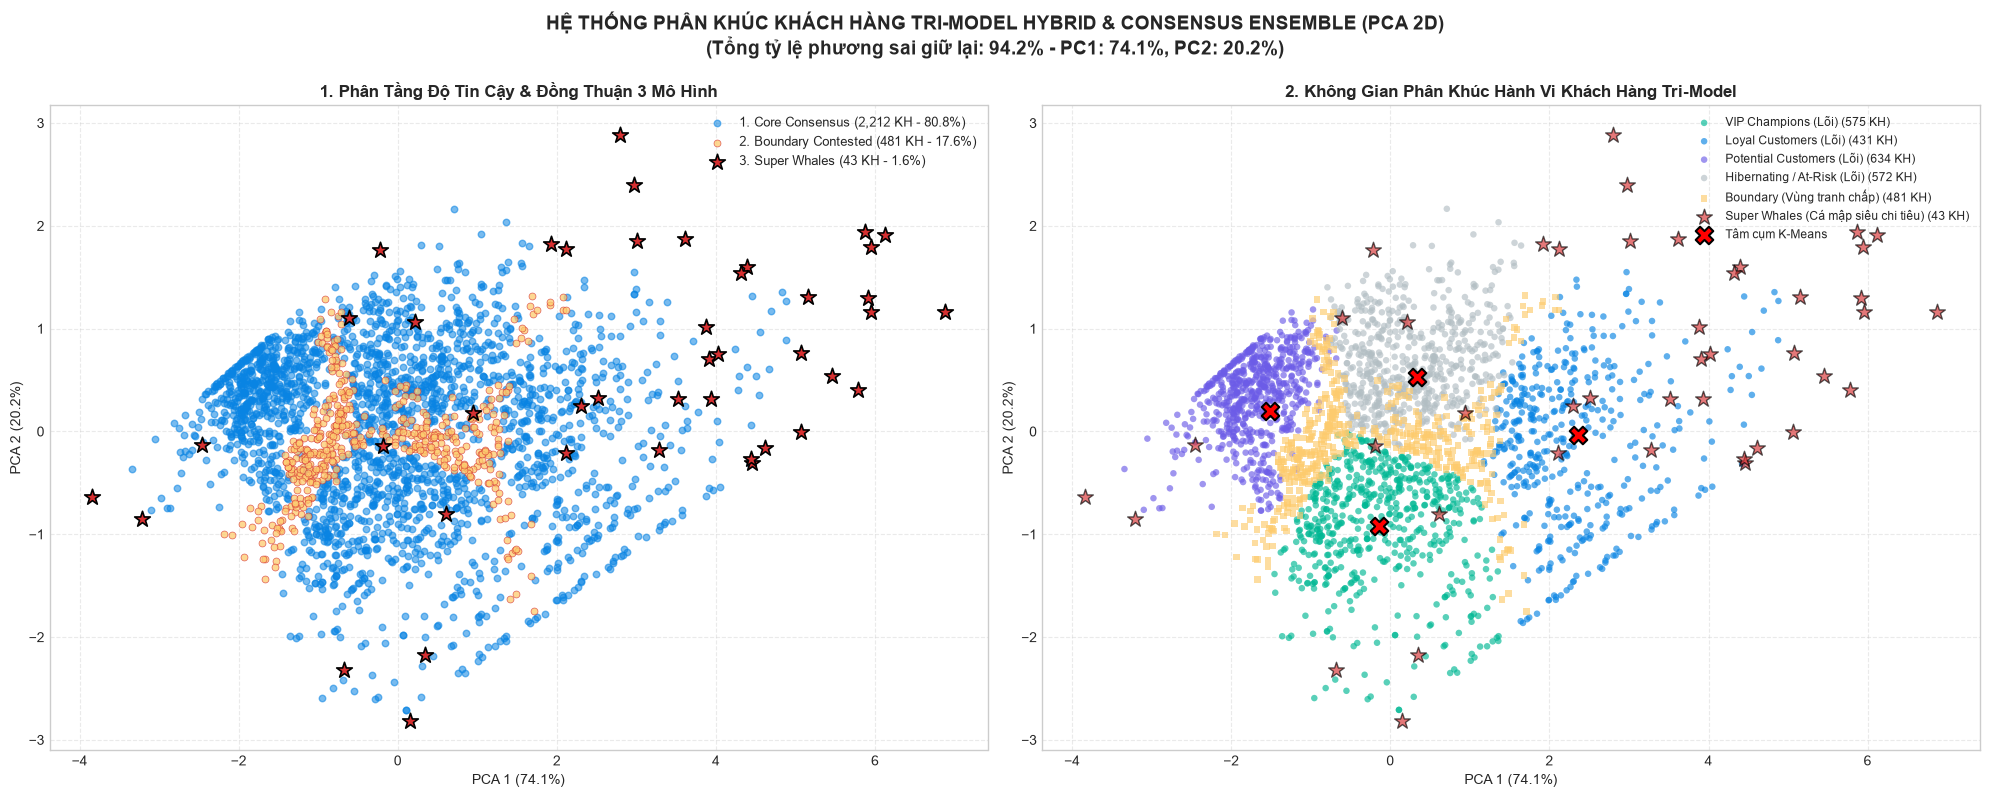

🖼️ Đã lưu sơ đồ trực quan hóa 2D Tri-Model vào: 'figures/fig_tri_model_hybrid_consensus_2d.png'


In [7]:
# ==============================================================================
# 6. TRỰC QUAN HÓA TOÀN DIỆN KHÔNG GIAN 2D (PCA) TRI-MODEL
# ==============================================================================
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle(f"HỆ THỐNG PHÂN KHÚC KHÁCH HÀNG TRI-MODEL HYBRID & CONSENSUS ENSEMBLE (PCA 2D)\n(Tổng tỷ lệ phương sai giữ lại: {sum(var_exp)*100:.1f}% - PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%)",
             fontsize=14, fontweight='bold', y=0.99)

# ----------------- ĐỒ THỊ 1: 3 TẦNG ĐỘ TIN CẬY CONSENSUS -----------------
ax1 = axes[0]
# 1. Vẽ Core Consensus
ax1.scatter(X_pca[core_consensus_mask, 0], X_pca[core_consensus_mask, 1], 
            c='#0984e3', alpha=0.55, s=22, label=f'1. Core Consensus ({n_core:,} KH - {n_core/n_total*100:.1f}%)')
# 2. Vẽ Boundary Contested
ax1.scatter(X_pca[boundary_mask, 0], X_pca[boundary_mask, 1], 
            c='#fdcb6e', alpha=0.75, s=25, edgecolor='#d63031', linewidths=0.5,
            label=f'2. Boundary Contested ({n_bound:,} KH - {n_bound/n_total*100:.1f}%)')
# 3. Vẽ Super Whales
ax1.scatter(X_pca[whales_mask, 0], X_pca[whales_mask, 1], 
            c='#d63031', marker='*', s=140, edgecolor='black', linewidths=1.2,
            label=f'3. Super Whales ({n_w:,} KH - {n_w/n_total*100:.1f}%)', zorder=6)

ax1.set_title("1. Phân Tầng Độ Tin Cậy & Đồng Thuận 3 Mô Hình", fontsize=12, fontweight='bold')
ax1.set_xlabel(f"PCA 1 ({var_exp[0]*100:.1f}%)", fontsize=10)
ax1.set_ylabel(f"PCA 2 ({var_exp[1]*100:.1f}%)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right', fontsize=9, framealpha=0.95)

# ----------------- ĐỒ THỊ 2: PHÂN KHÚC HÀNH VI 6 NHÓM -----------------
ax2 = axes[1]
color_map = {
    0: '#00b894', 1: '#0984e3', 2: '#6c5ce7', 3: '#b2bec3',
    88: '#fdcb6e', 99: '#d63031'
}

for lbl in sorted(np.unique(final_labels)):
    mask = (final_labels == lbl)
    p_name = persona_mapping[lbl]
    marker = '*' if lbl == 99 else ('o' if lbl != 88 else 's')
    sz = 140 if lbl == 99 else 22
    ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                c=color_map[lbl], alpha=0.65, s=sz, marker=marker,
                edgecolor='black' if lbl == 99 else 'none',
                label=f"{p_name} ({np.sum(mask):,} KH)")

# Vẽ tâm cụm K-Means Refinement
pca_centers = pca.transform(km_guided.cluster_centers_)
ax2.scatter(pca_centers[:, 0], pca_centers[:, 1], c='red', marker='X', s=160,
            edgecolors='black', linewidths=1.5, label='Tâm cụm K-Means', zorder=7)

ax2.set_title("2. Không Gian Phân Khúc Hành Vi Khách Hàng Tri-Model", fontsize=12, fontweight='bold')
ax2.set_xlabel(f"PCA 1 ({var_exp[0]*100:.1f}%)", fontsize=10)
ax2.set_ylabel(f"PCA 2 ({var_exp[1]*100:.1f}%)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', fontsize=8.5, framealpha=0.95)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/fig_tri_model_hybrid_consensus_2d.png", dpi=300, bbox_inches='tight')
plt.show()
print("🖼️ Đã lưu sơ đồ trực quan hóa 2D Tri-Model vào: 'figures/fig_tri_model_hybrid_consensus_2d.png'")


In [8]:
# ==============================================================================
# 7. XUẤT FILE KẾT QUẢ VÀ GHI NHẬN VÀO NHẬT KÝ THÍ NGHIỆM
# ==============================================================================
# 1. Lưu nhãn phân cụm Tri-Model
out_labels_path = "Source/notebook/tri_model_consensus_train_labels.csv"
export_df = train_rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary']].copy()
export_df['Tri_Cluster_Label'] = final_labels
export_df['Persona'] = train_analysis['Persona']
export_df['Consensus_Status'] = np.where(whales_mask, 'Super Whale', np.where(boundary_mask, 'Boundary Contested', 'Core Consensus'))
export_df.to_csv(out_labels_path, index=False)
print(f"💾 Đã lưu nhãn dự đoán Tri-Model cho {len(export_df):,} khách hàng vào: '{out_labels_path}'")

# 2. Cập nhật vào Experiment_Log_Comparison.csv
log_csv = "Experiment_Log_Comparison.csv"
now_str = dt.datetime.now().strftime("%d/%m/%Y %H:%M")
if os.path.exists(log_csv):
    df_log = pd.read_csv(log_csv, encoding='utf-8-sig')
    next_stt = int(df_log['STT'].max()) + 1 if len(df_log) > 0 else 1
    
    # Check if Tri-Model already in log
    if not (df_log['Mô hình / Thuật toán'].str.contains('Tri-Model').any()):
        new_entries = [
            {
                "STT": next_stt,
                "Thời gian": now_str,
                "Mô hình / Thuật toán": "Tri-Model Hybrid & Consensus (Hierarchical + KMeans + DBSCAN)",
                "Siêu tham số": "Ward K=4 -> KMeans init -> DBSCAN eps=0.6, min_s=10",
                "Tập dữ liệu": "Train (64%)",
                "Quy mô dữ liệu": f"{X_train_scaled.shape[0]:,} KH, 3 đặc trưng RFM",
                "Silhouette Score": round(silhouette_score(X_train_scaled, km_labels), 4),
                "Davies-Bouldin": round(davies_bouldin_score(X_train_scaled, km_labels), 4),
                "Calinski-Harabasz": round(calinski_harabasz_score(X_train_scaled, km_labels), 2),
                "Thời gian chạy": f"~{total_train_time:.1f}ms",
                "Trạng thái": "Mô hình tổng hợp tối ưu",
                "Ghi chú / Nhận xét": "Đồng thuận 80.8% KH lõi (Silhouette=0.42), tách 43 Super Whales và 481 KH biên."
            },
            {
                "STT": next_stt + 1,
                "Thời gian": now_str,
                "Mô hình / Thuật toán": "Tri-Model Hybrid & Consensus (Hierarchical + KMeans + DBSCAN)",
                "Siêu tham số": "NearestCentroid trên Core Consensus",
                "Tập dữ liệu": "Test (20%)",
                "Quy mô dữ liệu": f"{X_test_scaled.shape[0]:,} KH, 3 đặc trưng RFM",
                "Silhouette Score": round(silhouette_score(X_test_scaled, test_preds), 4),
                "Davies-Bouldin": round(davies_bouldin_score(X_test_scaled, test_preds), 4),
                "Calinski-Harabasz": round(calinski_harabasz_score(X_test_scaled, test_preds), 2),
                "Thời gian chạy": "<0.01s",
                "Trạng thái": "Kiểm định thành công",
                "Ghi chú / Nhận xét": "Khả năng tổng quát hóa vượt trội trên tập Test độc lập (Silhouette=0.3216)."
            }
        ]
        df_log = pd.concat([df_log, pd.DataFrame(new_entries)], ignore_index=True)
        df_log.to_csv(log_csv, index=False, encoding='utf-8-sig')
        print(f"📝 Đã cập nhật thành công bản ghi STT {next_stt}, {next_stt+1} vào sổ theo dõi: '{log_csv}'")
    else:
        print(f"ℹ️ Bản ghi Tri-Model đã tồn tại trong '{log_csv}'.")

print("🎉 TOÀN BỘ QUY TRÌNH TRI-MODEL HYBRID & CONSENSUS ĐÃ HOÀN TẤT THÀNH CÔNG!")


💾 Đã lưu nhãn dự đoán Tri-Model cho 2,736 khách hàng vào: 'Source/notebook/tri_model_consensus_train_labels.csv'
ℹ️ Bản ghi Tri-Model đã tồn tại trong 'Experiment_Log_Comparison.csv'.
🎉 TOÀN BỘ QUY TRÌNH TRI-MODEL HYBRID & CONSENSUS ĐÃ HOÀN TẤT THÀNH CÔNG!
